# Notebook métricas de evaluación con RR Lyrae

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

En esta actividad trabajaremos con un problema de clasificación binaria: distinguir estrellas **RR Lyrae** de otras estrellas a partir de sus colores fotométricos.

### Los objetivos son
- entrenar un clasificador simple
- evaluar su rendimiento con distintas métricas
- interpretar una matriz de confusión
- comparar accuracy con precision, recall y F1
- discutir qué métrica conviene según el objetivo científico

### Contexto
Las RR Lyrae son estrellas variables pulsantes muy importantes en astronomía. En un catálogo grande, un clasificador puede ayudarnos a encontrar candidatas RR Lyrae, pero no basta con mirar solo el accuracy.


### Descripción de los datos
El set de datos que usará para esta tarea es sobre estrellas. Las características son colores en distintos filtros del [sistema ugriz de SDSS](https://www.physics.unlv.edu/~jeffery/astro/photometry/photometry_sdss.html), que son un indicador si la estrella emite luz más azul, verde, amarilla o roja. Queremos predecir a partir de estas características si la estrella es un tipo especial de estrella llamada variable RR Lyrae.

- Las características son los colores u-g, g-r, r-i, i-z
- El target es 0 (no RRLyrae) y 1 (RRLyrae)


In [75]:
import pandas as pd
import numpy as np

import sklearn.tree
from sklearn.tree import DecisionTreeClassifier #modelo
from sklearn.tree import plot_tree #visualizacion arbol
from sklearn.model_selection import train_test_split
from sklearn import metrics #métricas
from sklearn.model_selection import cross_val_predict, cross_val_score, cross_validate #validación cruzada
from sklearn.model_selection import KFold, StratifiedKFold #validación cruzada

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay #matriz de confusión


from scipy import stats

In [76]:
from io import StringIO
from IPython.display import Image
import pydotplus
from sklearn.tree import export_graphviz

In [77]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

font = {'size': 8}

matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=8)
matplotlib.rc('ytick', labelsize=8)
matplotlib.rcParams['figure.dpi'] = 300

pd.set_option('display.max_columns', 100) #Para poder visualizar todas las columnas del dataframe
pd.set_option('display.max_colwidth', 100)

## Primer paso: exploración de los datos

Siempre es importante hacer una análisis exploratorio del conjunto de datos que trabajaremos. Leemos el archivo como un dataframe y extraemos información básica

In [78]:

features= np.loadtxt("RRLyrae_features_small.txt", delimiter=',')
targets= np.loadtxt("RRLyrae_labels_small.txt", delimiter=',')


In [79]:
columnas = ["u-g", "g-r", "r-i", "i-z"]
df = pd.DataFrame(features, columns=columnas)
df["RR_Lyrae"] = targets.astype(int)

df.head()

,u-g,g-r,r-i,i-z,RR_Lyrae
0,0.311,0.714,0.093,0.204,0
1,0.332,0.965,0.122,0.032,0
2,0.394,1.019,0.147,0.096,0
3,0.285,0.865,0.120,0.039,0
4,0.386,0.977,0.181,0.080,0


In [80]:
df.RR_Lyrae.value_counts()



,count
RR_Lyrae,
0,2000
1,483


In [81]:
print(df['RR_Lyrae'].value_counts(normalize=True))

RR_Lyrae
0    0.805477
1    0.194523
Name: proportion, dtype: float64


### Preguntas
1. ¿Este es un problema de clasificación o regresión?

Es un problema de clasificación, debemos clasificar las estrellas en las clases "no RRLyrae" o "RRLyrae".

2. ¿Es un problema binario o multiclase?

Es un problema binario car solo hay dos clases.

3. ¿Qué representa la variable objetivo?

El objectivo es de predecir la variable RR_Lyrae que puede valer 0 o 1 depende des la colores de las estrellas.

4. ¿Las clases están balanceadas o desbalanceadas?

Las clases estan desbalanceadas porque hay solo 483 RRLyrae para 2000 no RRLyrae pero este desbalance no es extremo.

5. ¿Por qué esto podría ser importante al elegir una métrica de evaluación?

Porque algunas métricas estan eficaces y pertinentes solo para los clases balanceadas.

#### Haga una visualización de sólo dos columnas para revisar los colores de las RR Lyrae y las no RRLyrae

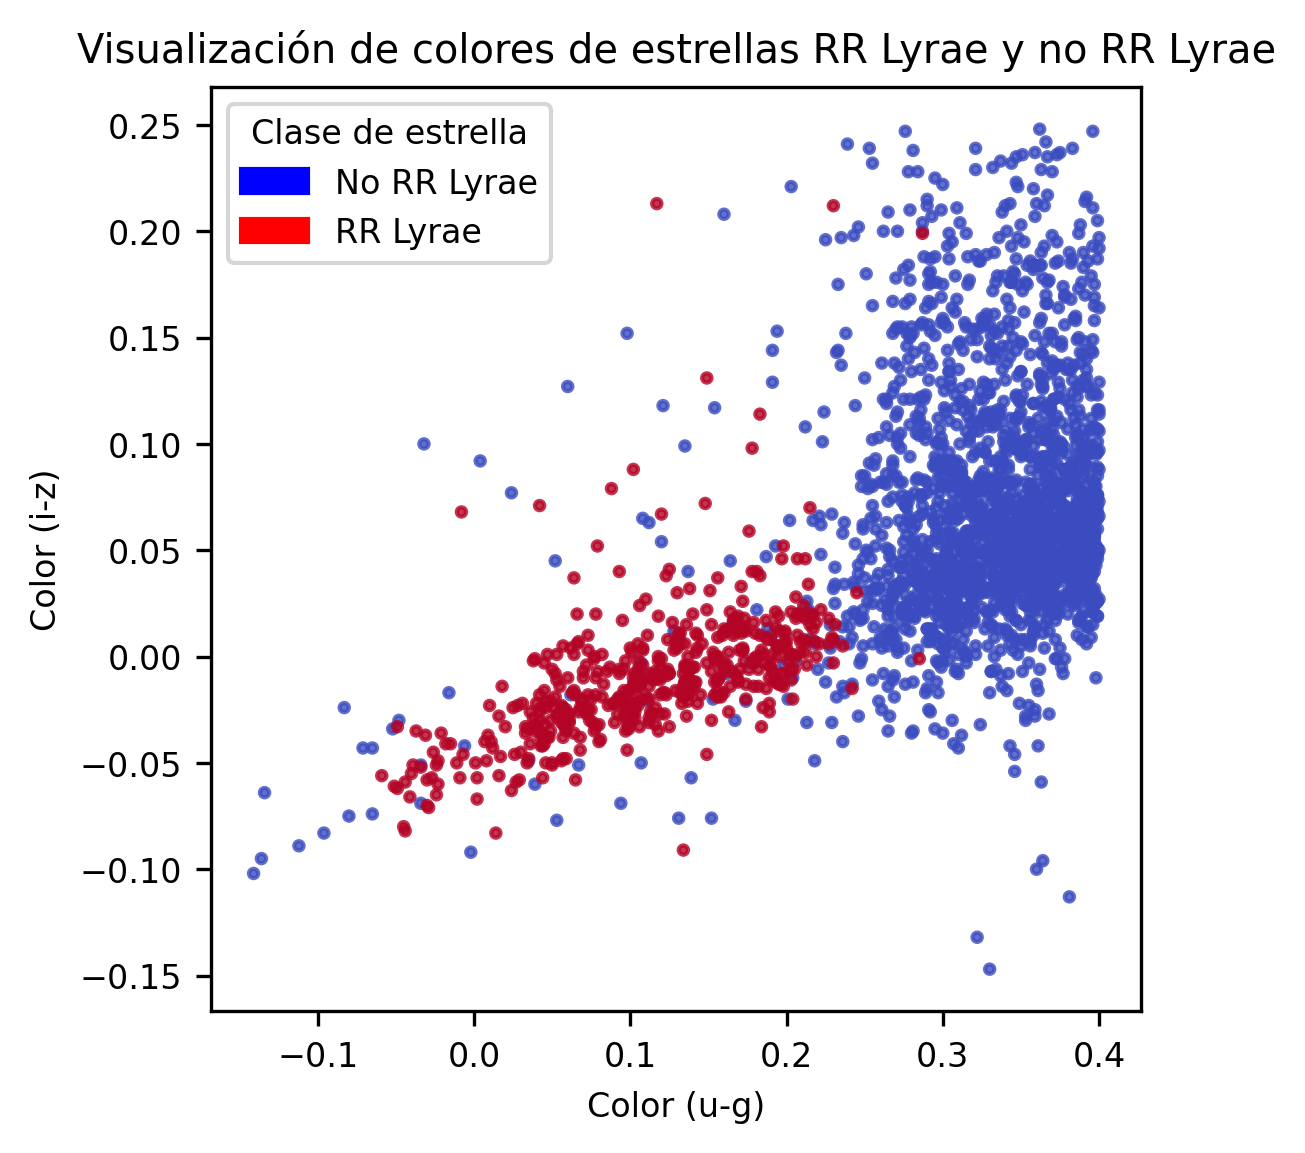

In [82]:
#complete la celda
plt.figure(figsize=(4,4))

sc=plt.scatter(df['u-g'], df['i-z'], c=df['RR_Lyrae'], cmap='coolwarm', s=5, alpha=0.8)

rrl = mpatches.Patch(color='red', label='RR Lyrae')
no_rrl = mpatches.Patch(color='blue', label='No RR Lyrae')
plt.legend(handles=[no_rrl, rrl], title='Clase de estrella')

plt.xlabel('Color (u-g)')
plt.ylabel('Color (i-z)')
plt.title('Visualización de colores de estrellas RR Lyrae y no RR Lyrae')
plt.show()

### Pregunta
1. ¿Se observan regiones donde las clases parecen separarse?

Con solo dos colores, no aparece regiones donde las clases parecen separarsee. Pero, de todos modos, hay una región en que no hay estrellas RR Lyrae.

2. A simple vista, ¿esperarías que un árbol de decisión funcione razonablemente bien?

De esta manera, que estas solo dos colores, pienso que un árbol de decisión no puede funcionar bien. Pero, con los qutros colores, pienso que podria functionnar.

#### Separe los datos en entrenamiento y prueba

In [83]:
X = df[["u-g", "g-r", "r-i", "i-z"]]
y = df["RR_Lyrae"]

In [84]:
#complete la celda
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size=0.3, random_state=42)

In [85]:
print("Proporción de RR Lyrae en el dataset completo:", y.value_counts(normalize=True))
print("Proporción de RR Lyrae en el dataset de entrenamiento:", y_train.value_counts(normalize=True))
print("Proporción de RR Lyrae en el dataset de prueba:", y_test.value_counts(normalize=True))

Proporción de RR Lyrae en el dataset completo: RR_Lyrae
0    0.805477
1    0.194523
Name: proportion, dtype: float64
Proporción de RR Lyrae en el dataset de entrenamiento: RR_Lyrae
0    0.796318
1    0.203682
Name: proportion, dtype: float64
Proporción de RR Lyrae en el dataset de prueba: RR_Lyrae
0    0.826846
1    0.173154
Name: proportion, dtype: float64


In [86]:
X_train.shape

(1738, 4)

### Antes de continuar

Las clases en este problema no están perfectamente balanceadas.

Piense en la forma en que podríamos separar los datos en entrenamiento y prueba, y responda:

1. ¿Qué problema podría ocurrir si hacemos la partición de manera completamente aleatoria, sin preocuparnos por la proporción de clases?

De manera completamente aleatoria, un problema que podría ocurrir seria que no hay casi ningun estrellas RR Lyrae en el set de pruebas.

2. ¿Por qué eso podría afectar la evaluación del modelo?

No podríamos verificar la detección de las estrellas RR Lyrae.

3. ¿Qué tipo de precaución cree que sería razonable tomar al construir los conjuntos de entrenamiento y prueba en este caso?

Creo que deberíamos imponer 0,3 de pruebas en las dos categorías de la clase. Eso es lo que hace el codigo entonces es perfecto.

#### Ahora entrenaremos un árbol de decisión (modelo base)

In [87]:
model_tree = DecisionTreeClassifier(random_state=42)
model_tree.fit(X_train, y_train)
#entrene el modelo y genere las predicciones
y_pred=model_tree.predict(X_test)


In [88]:
df.RR_Lyrae.value_counts()

,count
RR_Lyrae,
0,2000
1,483


#### Visualicemos el árbol

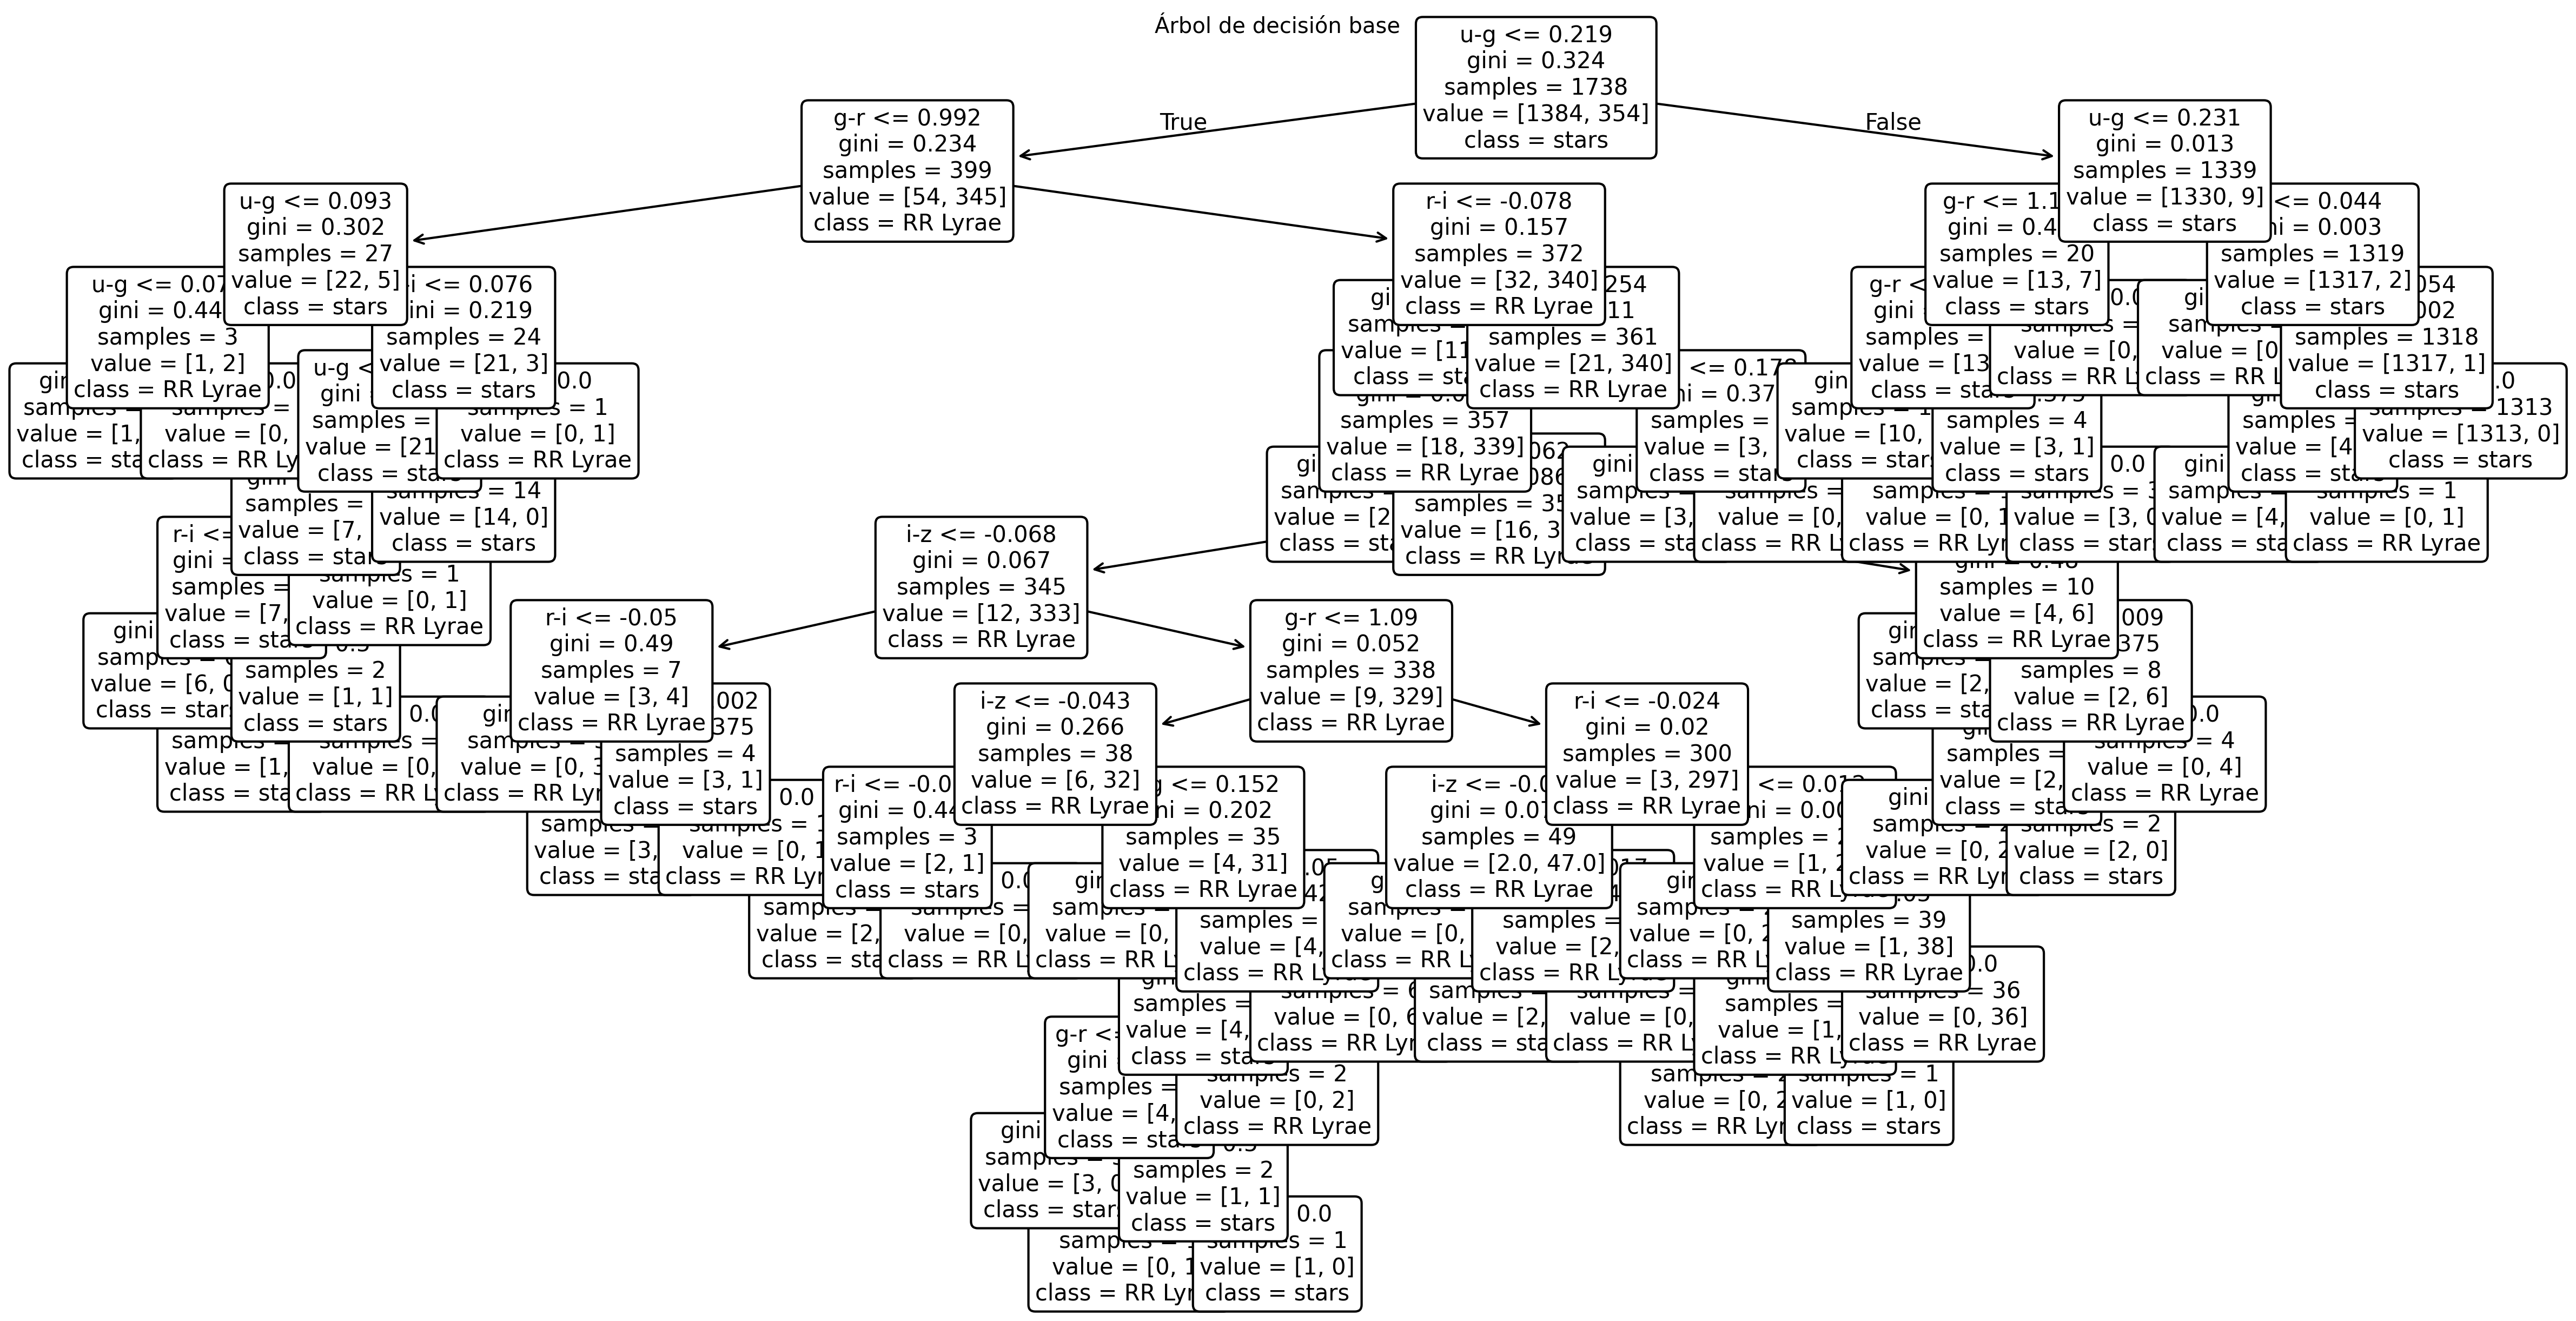

In [89]:
plt.figure(figsize=(20,10))

plot_tree(
    model_tree,
    feature_names=X.columns,
    class_names=["stars", "RR Lyrae"],
    filled=False,
    rounded=True,
    #max_depth=3,
    fontsize=10
)

plt.title("Árbol de decisión base")
plt.show()

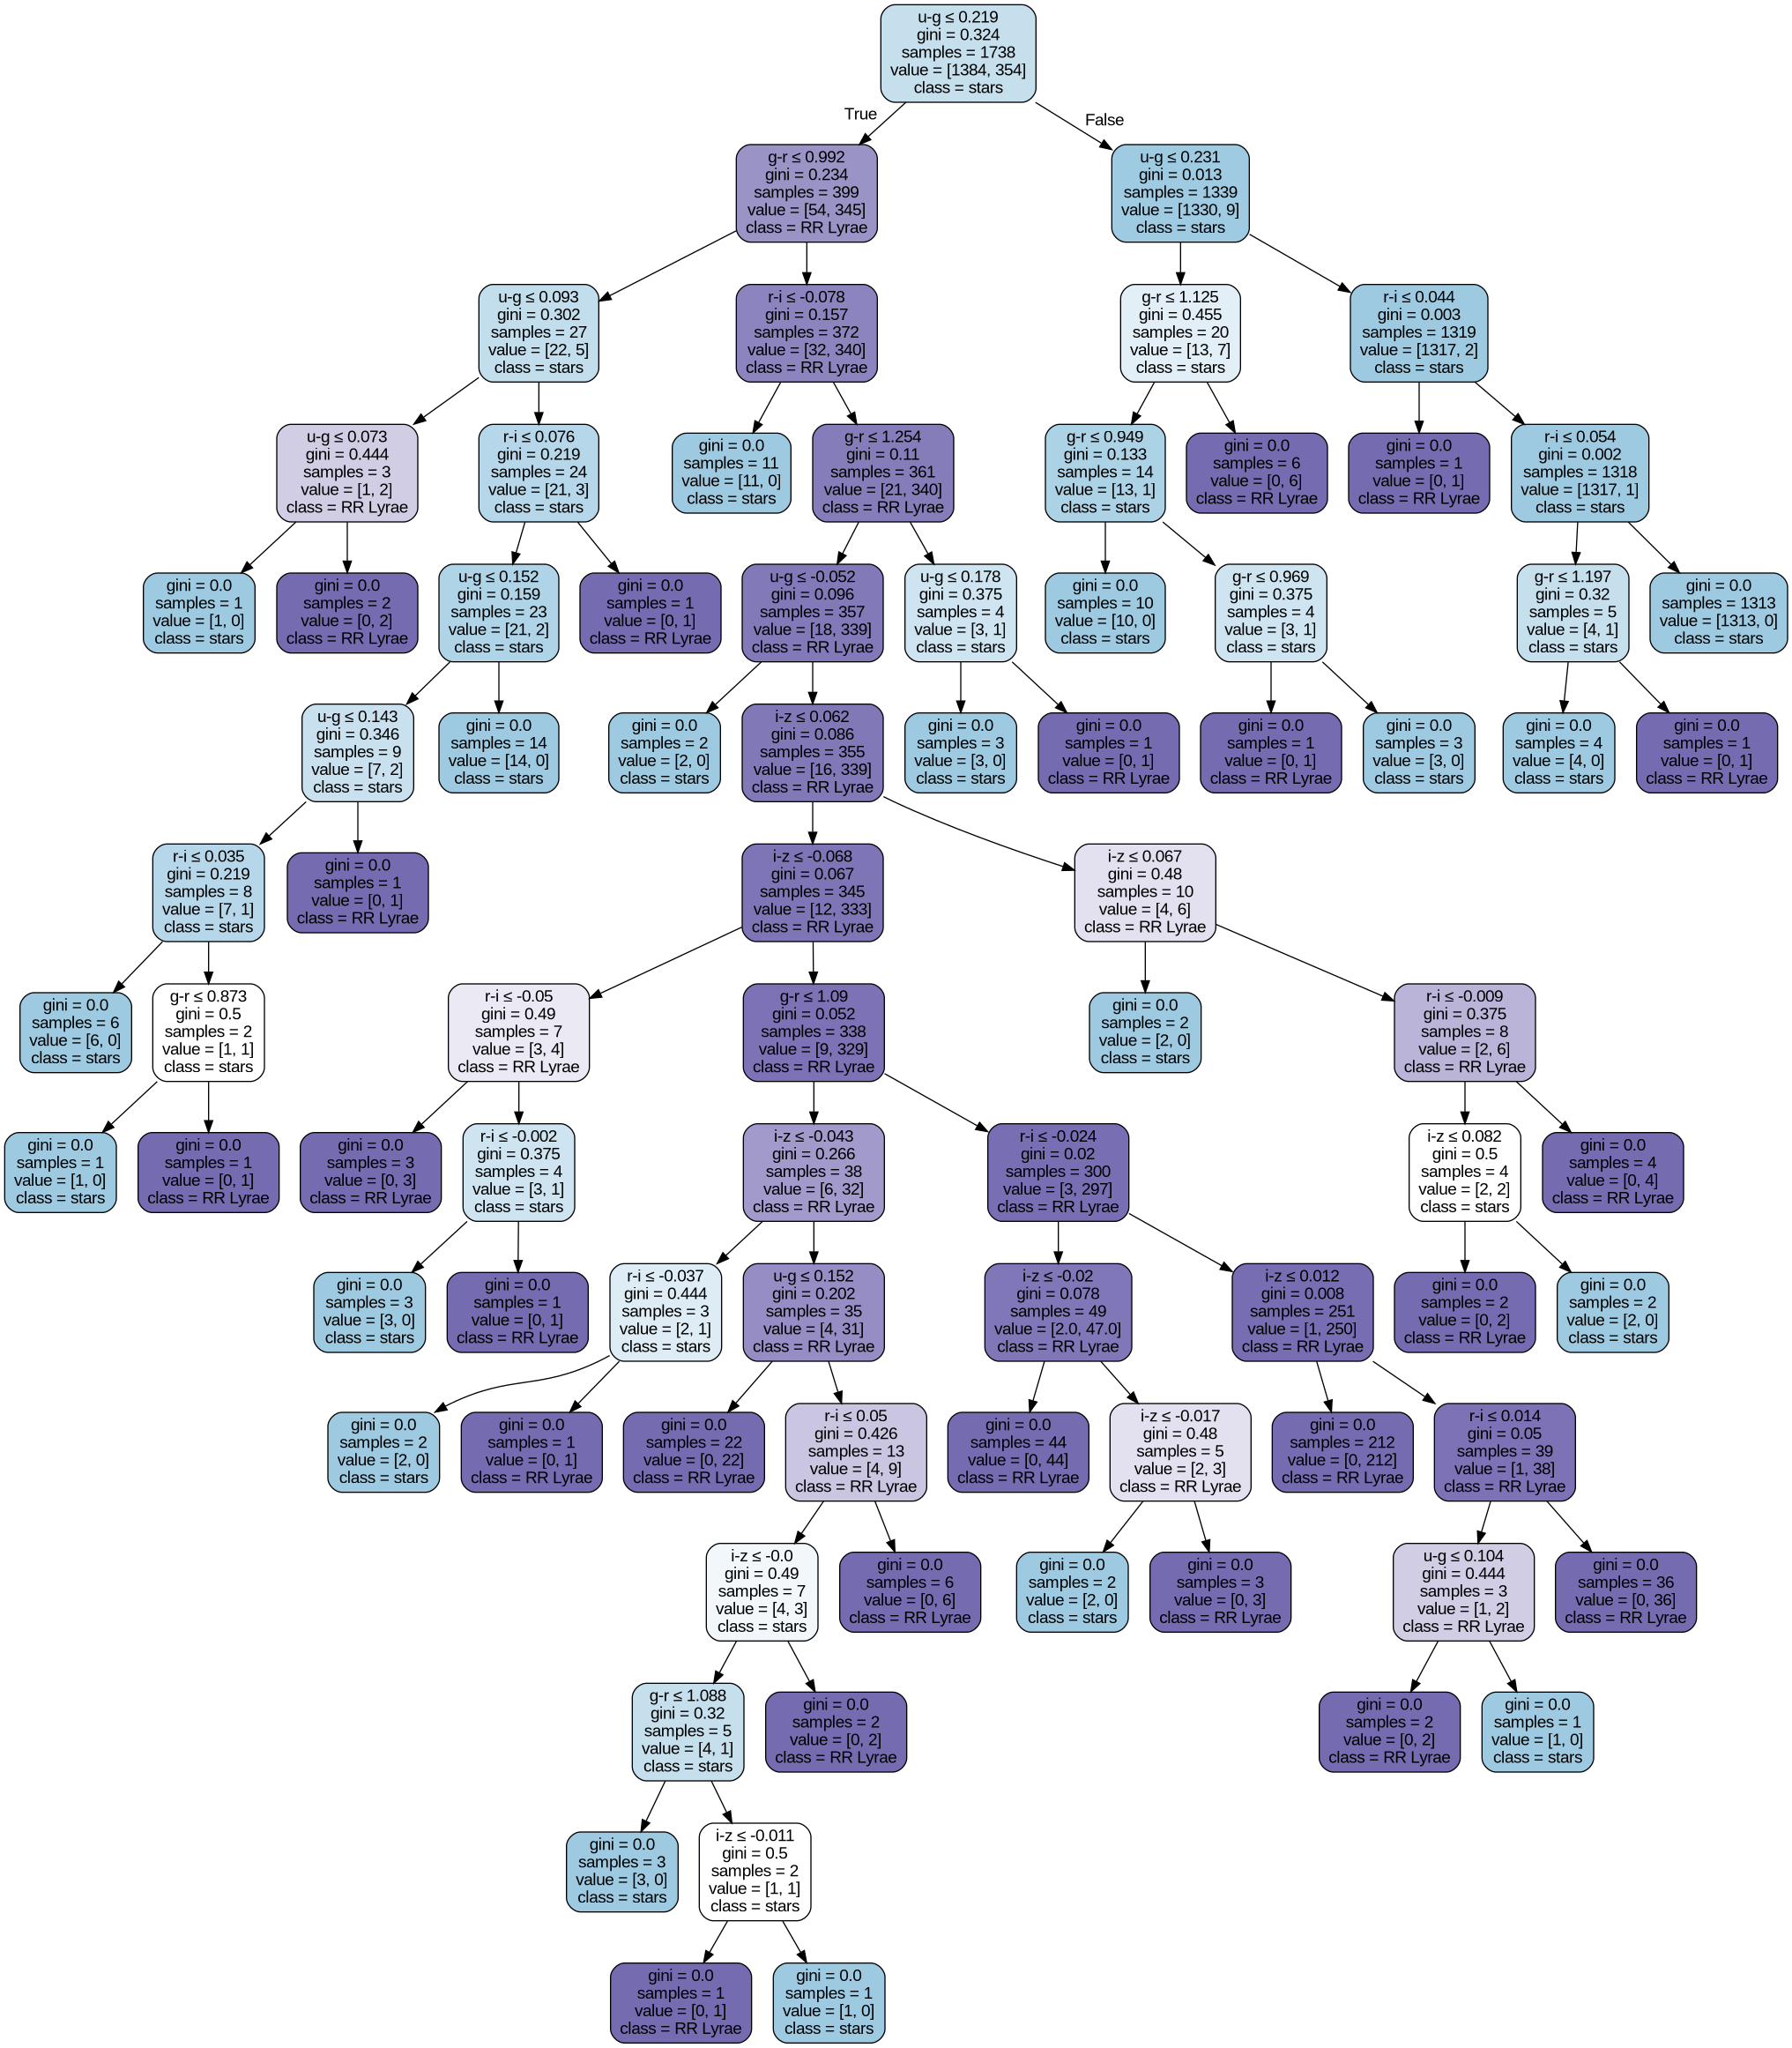

In [90]:
# Recordatorio: Las características siempre se permutan aleatoriamente en cada división.
# Por lo tanto, la mejor división encontrada puede variar, incluso con los mismos datos
# de entrenamiento y max_features=n_features, si la mejora del criterio es idéntica
# para varias divisiones enumeradas durante la búsqueda de la mejor división.
# Para obtener un comportamiento determinista durante el ajuste, random_state debe estar fijo.

dot_data = StringIO()

export_graphviz(
    model_tree,
    out_file=dot_data,
    feature_names=['u-g', 'g-r', 'r-i', 'i-z'],
    class_names=['stars', 'RR Lyrae'],
    filled=True,
    rounded=True,
    special_characters=True
)

graph = pydotplus.graph_from_dot_data(dot_data.getvalue().replace("\n", ""))
nodes = graph.get_node_list()

for node in nodes:
    if node.get_label() and 'value = [' in node.get_label():

        values = [float(ii) for ii in node.get_label().split('value = [')[1].split(']')[0].split(',')]
        values = [int(255 * v / sum(values)) for v in values]

        if values[0] > values[1]:
            alpha = int(values[0] - values[1])
            alpha = '{:02x}'.format(alpha)
            color = '#9ecae1' + str(alpha)   # turquesa
        else:
            alpha = int(values[1] - values[0])
            alpha = '{:02x}'.format(alpha)
            color = '#756bb1' + str(alpha)   # magenta

        node.set_fillcolor(color)

Image(graph.create_png())

### Preguntas

Observe la estructura del árbol y responda brevemente:

1. ¿El árbol parece muy simple o bastante complejo? Justifique a partir del número de niveles o divisiones.

El árbol parece bastante complejo. Tiene una profundida de 14 y 50, divisiones para solo 4 variables de estudio. Creo que un arboles con 10 divisiones podría ser suficiente.

2. ¿Qué desventaja podría tener un árbol demasiado grande en un problema como este?

El árbol podría sobre-ajustar y también consumir demasiados recursos de cálculo.

#### Miremos las métricas accuracy para set de entrenamiento y prueba

In [91]:
print(metrics.accuracy_score(y_train, model_tree.predict(X_train))) #train score

print(metrics.accuracy_score(y_test, model_tree.predict(X_test))) #test score

1.0
0.9651006711409396


#### Otras métricas

In [92]:
print("Precision:", metrics.precision_score(y_test, y_pred))
print("Recall   :", metrics.recall_score(y_test, y_pred))
print("F1-score :", metrics.f1_score(y_test, y_pred))

Precision: 0.8759124087591241
Recall   : 0.9302325581395349
F1-score : 0.9022556390977443


In [93]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[599,  17],
       [  9, 120]])

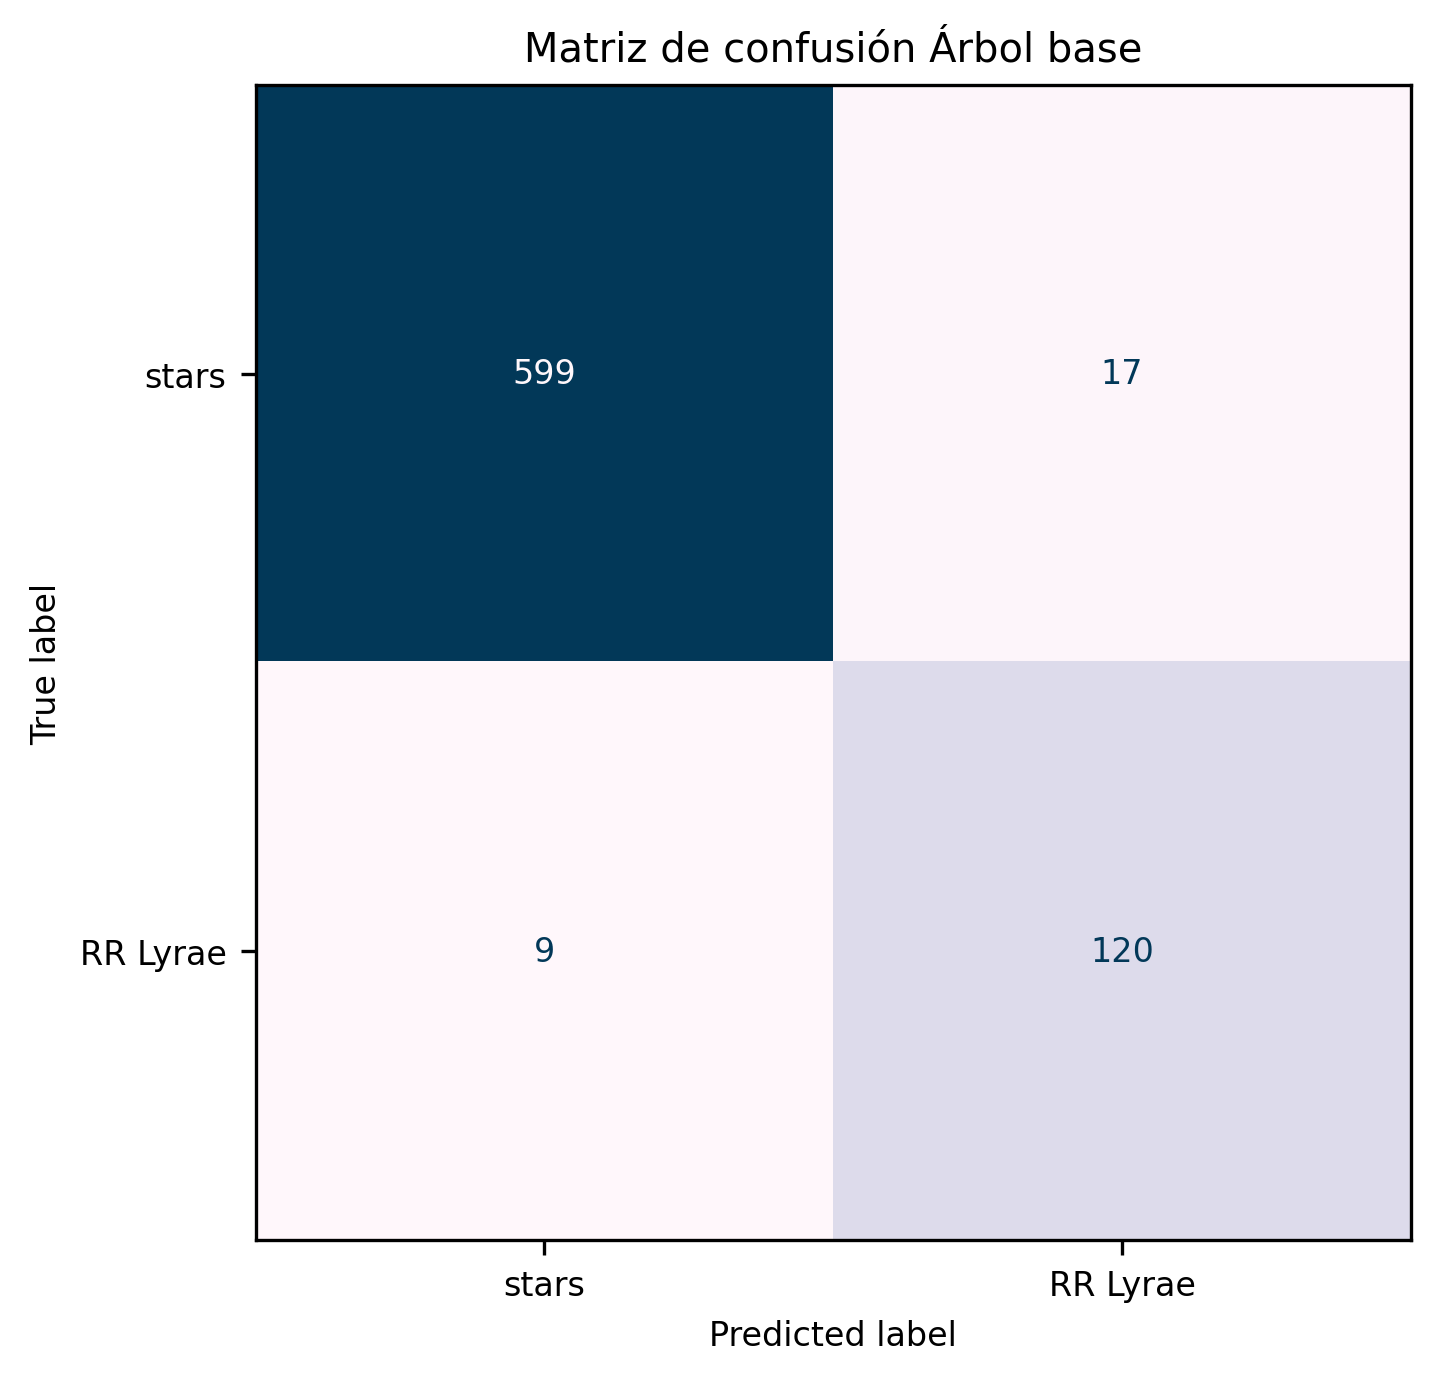

In [94]:
fig, ax = plt.subplots(figsize=(5,5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["stars", "RR Lyrae"])
disp.plot(cmap="PuBu", ax=ax, colorbar=False)

plt.title("Matriz de confusión Árbol base")
plt.show()

#### A partir de la matriz de confusión obtenida:
1.  Identifique los valores de:
   - verdaderos positivos (TP) 136
   - verdaderos negativos (TN) 593
   - falsos positivos (FP) 7
   - falsos negativos (FN) 9
2. Calcule las métricas "a mano"

Accuracy = (TN+TP) / Total = (136+593) / 745 = 0.9785

Precision = TP / (FP+TP) = 136 / (136+7) = 0.9510

Recall = TP / (FN+TP) = 136 / (136+9) = 0.9379

F1_score = 2.Pr.Rec / (Pr+Rec) = 2 . 0,9510 . 0,9379 / ( 0,9510 + 0,9379 ) = 0,9444



### Preguntas
1. Explique con sus palabras qué significa, en este problema:
   - un falso positivo: El árbol indica que es una RR Lyrae, pero no lo es; el árbol da un valor positivo de 1, pero no debería.
   - un falso negativo: El árbol indica que no es una RR Lyrae, pero sí lo es; el árbol da un valor de 0, pero debería dar un valor de 1.

2. Si el objetivo científico fuera encontrar la mayor cantidad posible de RR Lyrae, ¿qué tipo de error preocuparía más?

Las falsos negativos porque vamos a olvidar muchas estrellas RR Lyrae si este valor es grande. Entonces estudimos el Recall.

3. Si el objetivo fuera construir una muestra final más limpia, ¿qué tipo de error preocuparía más?

Para una luestra limpia debemos tener pequnas cantidad de falsos negativos pero tambien de falso positivo y entonces mirar al F1_score.

#### Todo parece funcionar bien, pero sólo hicimos un split. Necesitamos que el resultados sea robusto. Para esto, implementaremos Cross-validation usando [k-fold](https://scikit--learn-org.translate.goog/stable/modules/generated/sklearn.model_selection.KFold.html?_x_tr_sl=en&_x_tr_tl=es&_x_tr_hl=es&_x_tr_pto=tc)

In [95]:
# Esta es la versión estándar. Importante: no baraja los datos, por lo que si tus
# ejemplos positivos están todos al principio o al final, podría llevar a resultados
# desastrosos.

cv1 = KFold(n_splits = 5)

#Esta es la versión 2: se ha añadido el barajado (¡recomendado!)

cv2 = KFold(shuffle = True, n_splits = 5, random_state=5)

# LA ESTRATIFICACIÓN asegura que las distribuciones de clases en cada división se
# asemejen a las del conjunto de datos completo.

cv3 = StratifiedKFold(shuffle = True, n_splits = 5, random_state=5)


### Efecto de la estratificación: veamos el conteo de clases en cada conjunto de divisiones.

In [96]:
cv1.split(X, y)

<generator object _BaseKFold.split at 0x789ea16af450>

In [97]:
for train, test in cv1.split(X, y):
     print('train -  {}   |   test -  {}'.format(np.bincount(y.loc[train]), np.bincount(y.loc[test])))

train -  [1503  483]   |   test -  [497]
train -  [1503  483]   |   test -  [497]
train -  [1503  483]   |   test -  [497]
train -  [1504  483]   |   test -  [496]
train -  [1987]   |   test -  [ 13 483]


In [98]:
for train, test in cv2.split(X, y):
     print('train -  {}   |   test -  {}'.format( np.bincount(y.loc[train]), np.bincount(y.loc[test])))

train -  [1600  386]   |   test -  [400  97]
train -  [1610  376]   |   test -  [390 107]
train -  [1587  399]   |   test -  [413  84]
train -  [1599  388]   |   test -  [401  95]
train -  [1604  383]   |   test -  [396 100]


In [99]:
for train, test in cv3.split(X, y):
     print('train -  {}   |   test -  {}'.format(np.bincount(y.loc[train]), np.bincount(y.loc[test])))

train -  [1600  386]   |   test -  [400  97]
train -  [1600  386]   |   test -  [400  97]
train -  [1600  386]   |   test -  [400  97]
train -  [1600  387]   |   test -  [400  96]
train -  [1600  387]   |   test -  [400  96]


### La función [`cross_validate`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html#sklearn.model_selection.cross_validate) proporciona los puntajes (especificados por el parámetro de evaluación elegido), en forma de diccionario.

In [100]:
scores1 = cross_validate(DecisionTreeClassifier(), X, y, cv = cv1, scoring = 'accuracy')

scores2 = cross_validate(DecisionTreeClassifier(), X, y, cv = cv2, scoring = 'accuracy')

scores3 = cross_validate(DecisionTreeClassifier(), X, y, cv = cv3, scoring = 'accuracy')

In [101]:
scores3

{'fit_time': array([0.00986004, 0.00863051, 0.01055145, 0.01171255, 0.00947237]),
 'score_time': array([0.00382042, 0.00353861, 0.00385714, 0.00371647, 0.00764179]),
 'test_score': array([0.98390342, 0.96780684, 0.96579477, 0.97983871, 0.9516129 ])}

Solo nos interesa el 'test_score'

#### Calculamos el promedio y $\sigma$

In [102]:
print("{:.3f}".format(scores1['test_score'].mean()), "{:.3f}".format(scores1['test_score'].std()))

0.786 0.380


In [103]:
print("{:.3f}".format(scores2['test_score'].mean()), "{:.3f}".format(scores2['test_score'].std()))

0.967 0.010


In [104]:
print("{:.3f}".format(scores3['test_score'].mean()), "{:.3f}".format(scores3['test_score'].std()))

0.970 0.011


La validación cruzada sin barajar (`cv1`) produce un resultado muy inestable, con una desviación estándar extremadamente alta. Esto ocurre porque los datos están ordenados por clase, de modo que algunos folds no representan bien el problema completo.

Al activar el barajado (`cv2`), el rendimiento mejora drásticamente y la dispersión disminuye. Sin embargo, el método que resulta más apropiado para este problema es `StratifiedKFold` (`cv3`), ya que además de mezclar los datos, conserva aproximadamente la proporción de clases en cada fold.

En problemas de clasificación desbalanceada, esta última estrategia suele ser la más recomendable.

In [105]:
scores1 = cross_validate(DecisionTreeClassifier(random_state=1), X,y, cv = cv1, scoring = 'recall')

scores2 = cross_validate(DecisionTreeClassifier(random_state=1), X,y, cv = cv2, scoring = 'recall')

scores3 = cross_validate(DecisionTreeClassifier(random_state=1), X,y, cv = cv3, scoring = 'recall')

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricW

In [106]:
print("{:.3f}".format(scores1['test_score'].mean()), "{:.3f}".format(scores1['test_score'].std()))
print("{:.3f}".format(scores2['test_score'].mean()), "{:.3f}".format(scores2['test_score'].std()))
print("{:.3f}".format(scores3['test_score'].mean()), "{:.3f}".format(scores3['test_score'].std()))

nan nan
0.903 0.016
0.925 0.019


### ¿Por qué aparece este warning?

En algunos folds generados por `KFold` sin barajado, el conjunto de prueba contiene solo ejemplos de una clase. En ese caso, el recall de la clase positiva (RR Lyrae) no puede calcularse, porque no hay positivos reales en ese fold.

Esto muestra que una estrategia de partición inadecuada puede hacer que la evaluación sea inestable, engañosa o incluso inválida.

#### También extraeremos los train scores, que nos servirán cuando estemos diagnosticando el modelo a través de bias vs variance.¶

In [107]:
scores1 = cross_validate(DecisionTreeClassifier(), X,y, cv = cv1, scoring = 'recall', \
                         return_train_score = True)

scores2 = cross_validate(DecisionTreeClassifier(), X,y, cv = cv2, scoring = 'recall', \
                         return_train_score = True)

scores3 = cross_validate(DecisionTreeClassifier(), X,y, cv = cv3, scoring = 'recall',
                         return_train_score = True)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricW

In [108]:
print("{:.3f}".format(scores1['test_score'].mean()), "{:.3f}".format(scores1['train_score'].mean()))
print("{:.3f}".format(scores2['test_score'].mean()), "{:.3f}".format(scores2['train_score'].mean()))
print("{:.3f}".format(scores3['test_score'].mean()), "{:.3f}".format(scores3['train_score'].mean()))

nan nan
0.908 1.000
0.934 1.000


### La función  `cross_validate` es útil para calcular el puntaje, pero no produce etiquetas predichas.

#### Estas pueden obtenerse utilizando la función [`cross_val_predict`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html), que guarda las predicciones para cada uno de los k-folds de prueba y las compila juntas.


In [109]:
model1 = DecisionTreeClassifier(random_state = 3)

y_cv3 = cross_val_predict(model1, X,y, cv = cv3)
# Estas son las predicciones,
# y son independientes del parámetro de evaluación

In [110]:
metrics.confusion_matrix(targets,y_cv3)

array([[1955,   45],
       [  33,  450]])

### Sin embargo, las cosas pueden cambiar si uso un esquema de validación cruzada diferente:

In [111]:
model2 = DecisionTreeClassifier(random_state = 3)

y_cv2 = cross_val_predict(model2, X,y, cv = cv2)

In [112]:
np.sum(y_cv3-y_cv2)

np.int64(10)

In [113]:
np.sum(y_cv2)

np.int64(485)

In [114]:
np.sum(y_cv3 != y_cv2) #comparando las predicciones

np.int64(52)

In [115]:
metrics.confusion_matrix(targets,y_cv2)

array([[1955,   45],
       [  43,  440]])

In [116]:
metrics.confusion_matrix(targets,y_cv3)

array([[1955,   45],
       [  33,  450]])

In [117]:
from sklearn.model_selection import learning_curve

def plot_learning_curve(estimator, title, X, y, ylim=None, cv=5,
                        n_jobs=-1, train_sizes=np.linspace(0.2, 1.0, 5), scoring = 'accuracy'):
    """
    Generate a simple plot of the test and training learning curve.

    Parameters
    ----------
    estimator : object type that implements the "fit" and "predict" methods
        An object of that type which is cloned for each validation.

    title : string
        Title for the chart.

    X : array-like, shape (n_samples, n_features)
        Training vector, where n_samples is the number of samples and
        n_features is the number of features.

    y : array-like, shape (n_samples) or (n_samples, n_features), optional
        Target relative to X for classification or regression;
        None for unsupervised learning.

    ylim : tuple, shape (ymin, ymax), optional
        Defines minimum and maximum yvalues plotted.

    cv : int, cross-validation generator or an iterable, optional
        Determines the cross-validation splitting strategy.
        Possible inputs for cv are:
          - None, to use the default 3-fold cross-validation,
          - integer, to specify the number of folds.
          - :term:`CV splitter`,
          - An iterable yielding (train, test) splits as arrays of indices.

        For integer/None inputs, if ``y`` is binary or multiclass,
        :class:`StratifiedKFold` used. If the estimator is not a classifier
        or if ``y`` is neither binary nor multiclass, :class:`KFold` is used.

        Refer :ref:`User Guide <cross_validation>` for the various
        cross-validators that can be used here.

    n_jobs : int or None, optional (default=None)
        Number of jobs to run in parallel.
        ``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.
        ``-1`` means using all processors. See :term:`Glossary <n_jobs>`
        for more details.

    train_sizes : array-like, shape (n_ticks,), dtype float or int
        Relative or absolute numbers of training examples that will be used to
        generate the learning curve. If the dtype is float, it is regarded as a
        fraction of the maximum size of the training set (that is determined
        by the selected validation method), i.e. it has to be within (0, 1].
        Otherwise it is interpreted as absolute sizes of the training sets.
        Note that for classification the number of samples usually have to
        be big enough to contain at least one sample from each class.
        (default: np.linspace(0.1, 1.0, 5))
    """
    plt.figure(figsize=(10,6))
    plt.title(title)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.xlabel("Training examples")
    plt.ylabel(str(scoring))

    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes, scoring = scoring, shuffle=True, random_state=42)
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)
    plt.grid()

    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1,
                     color="r")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="g")
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r",
             label="Training score")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g",
             label="Test score from cross-validation")

    plt.legend(loc="best")
    return plt

In [118]:
model = DecisionTreeClassifier(random_state = 5)

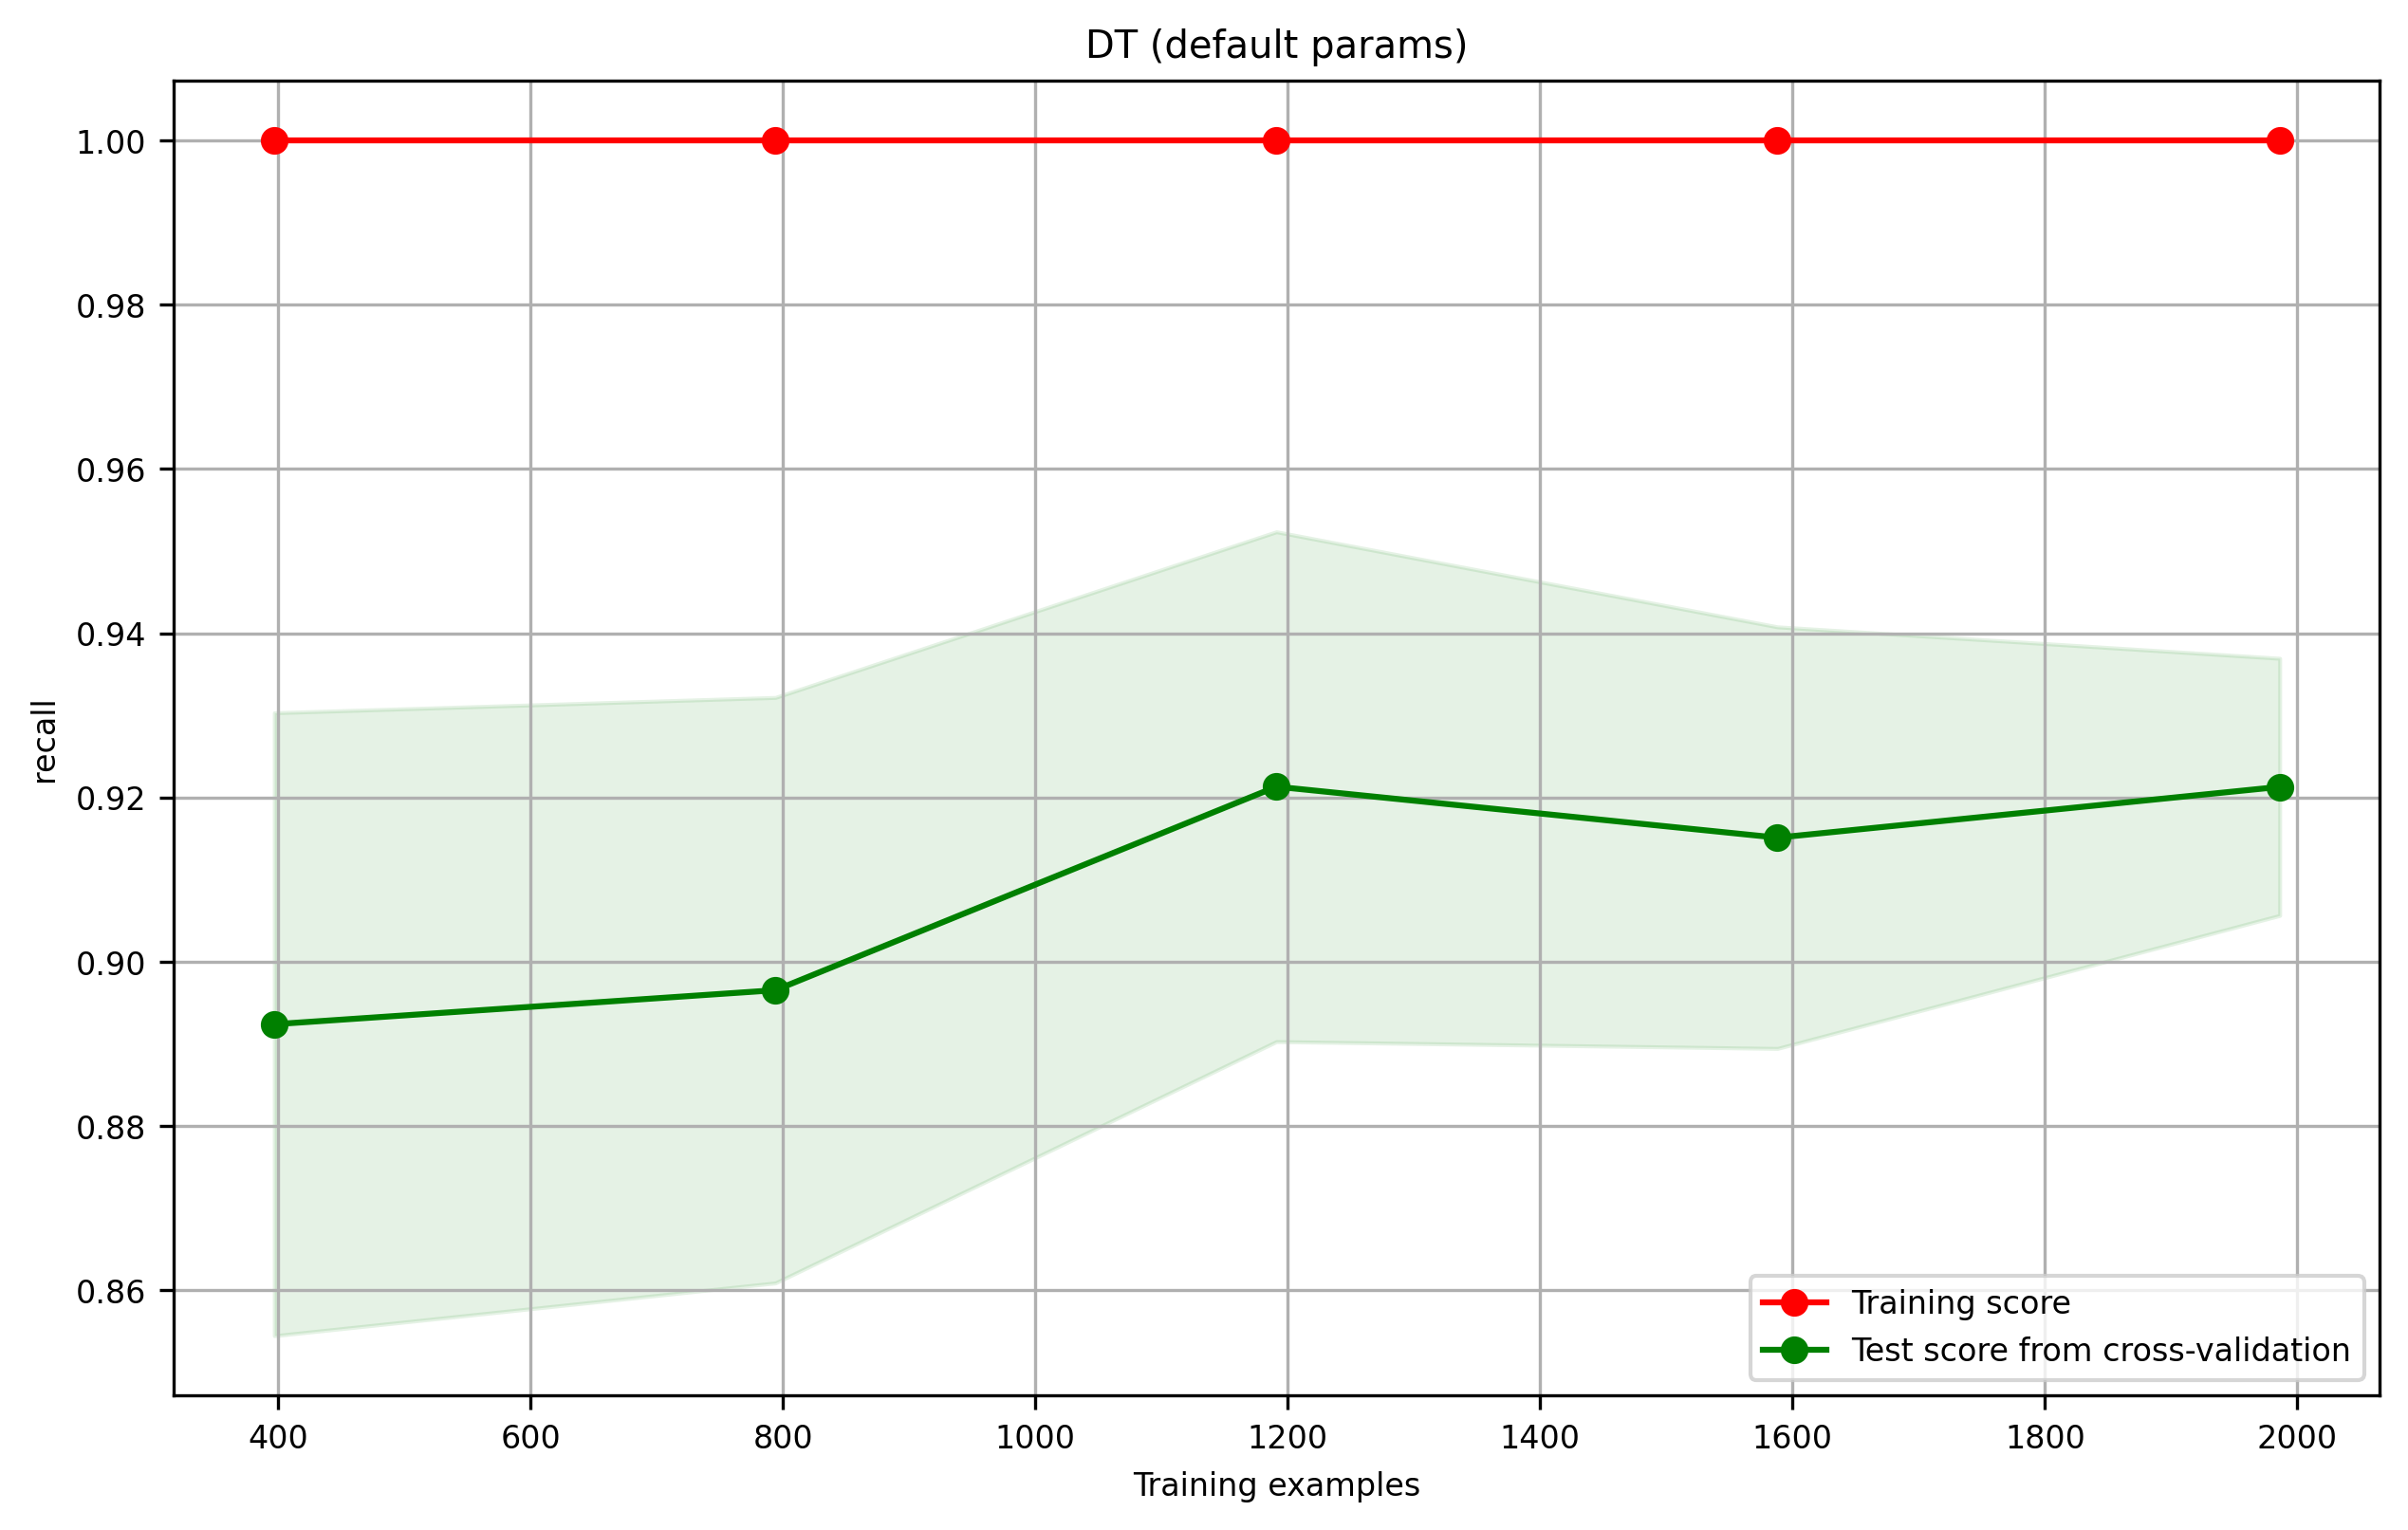

In [119]:
plot_learning_curve(model, 'DT (default params)', X, y,  cv = cv3, scoring = 'recall');

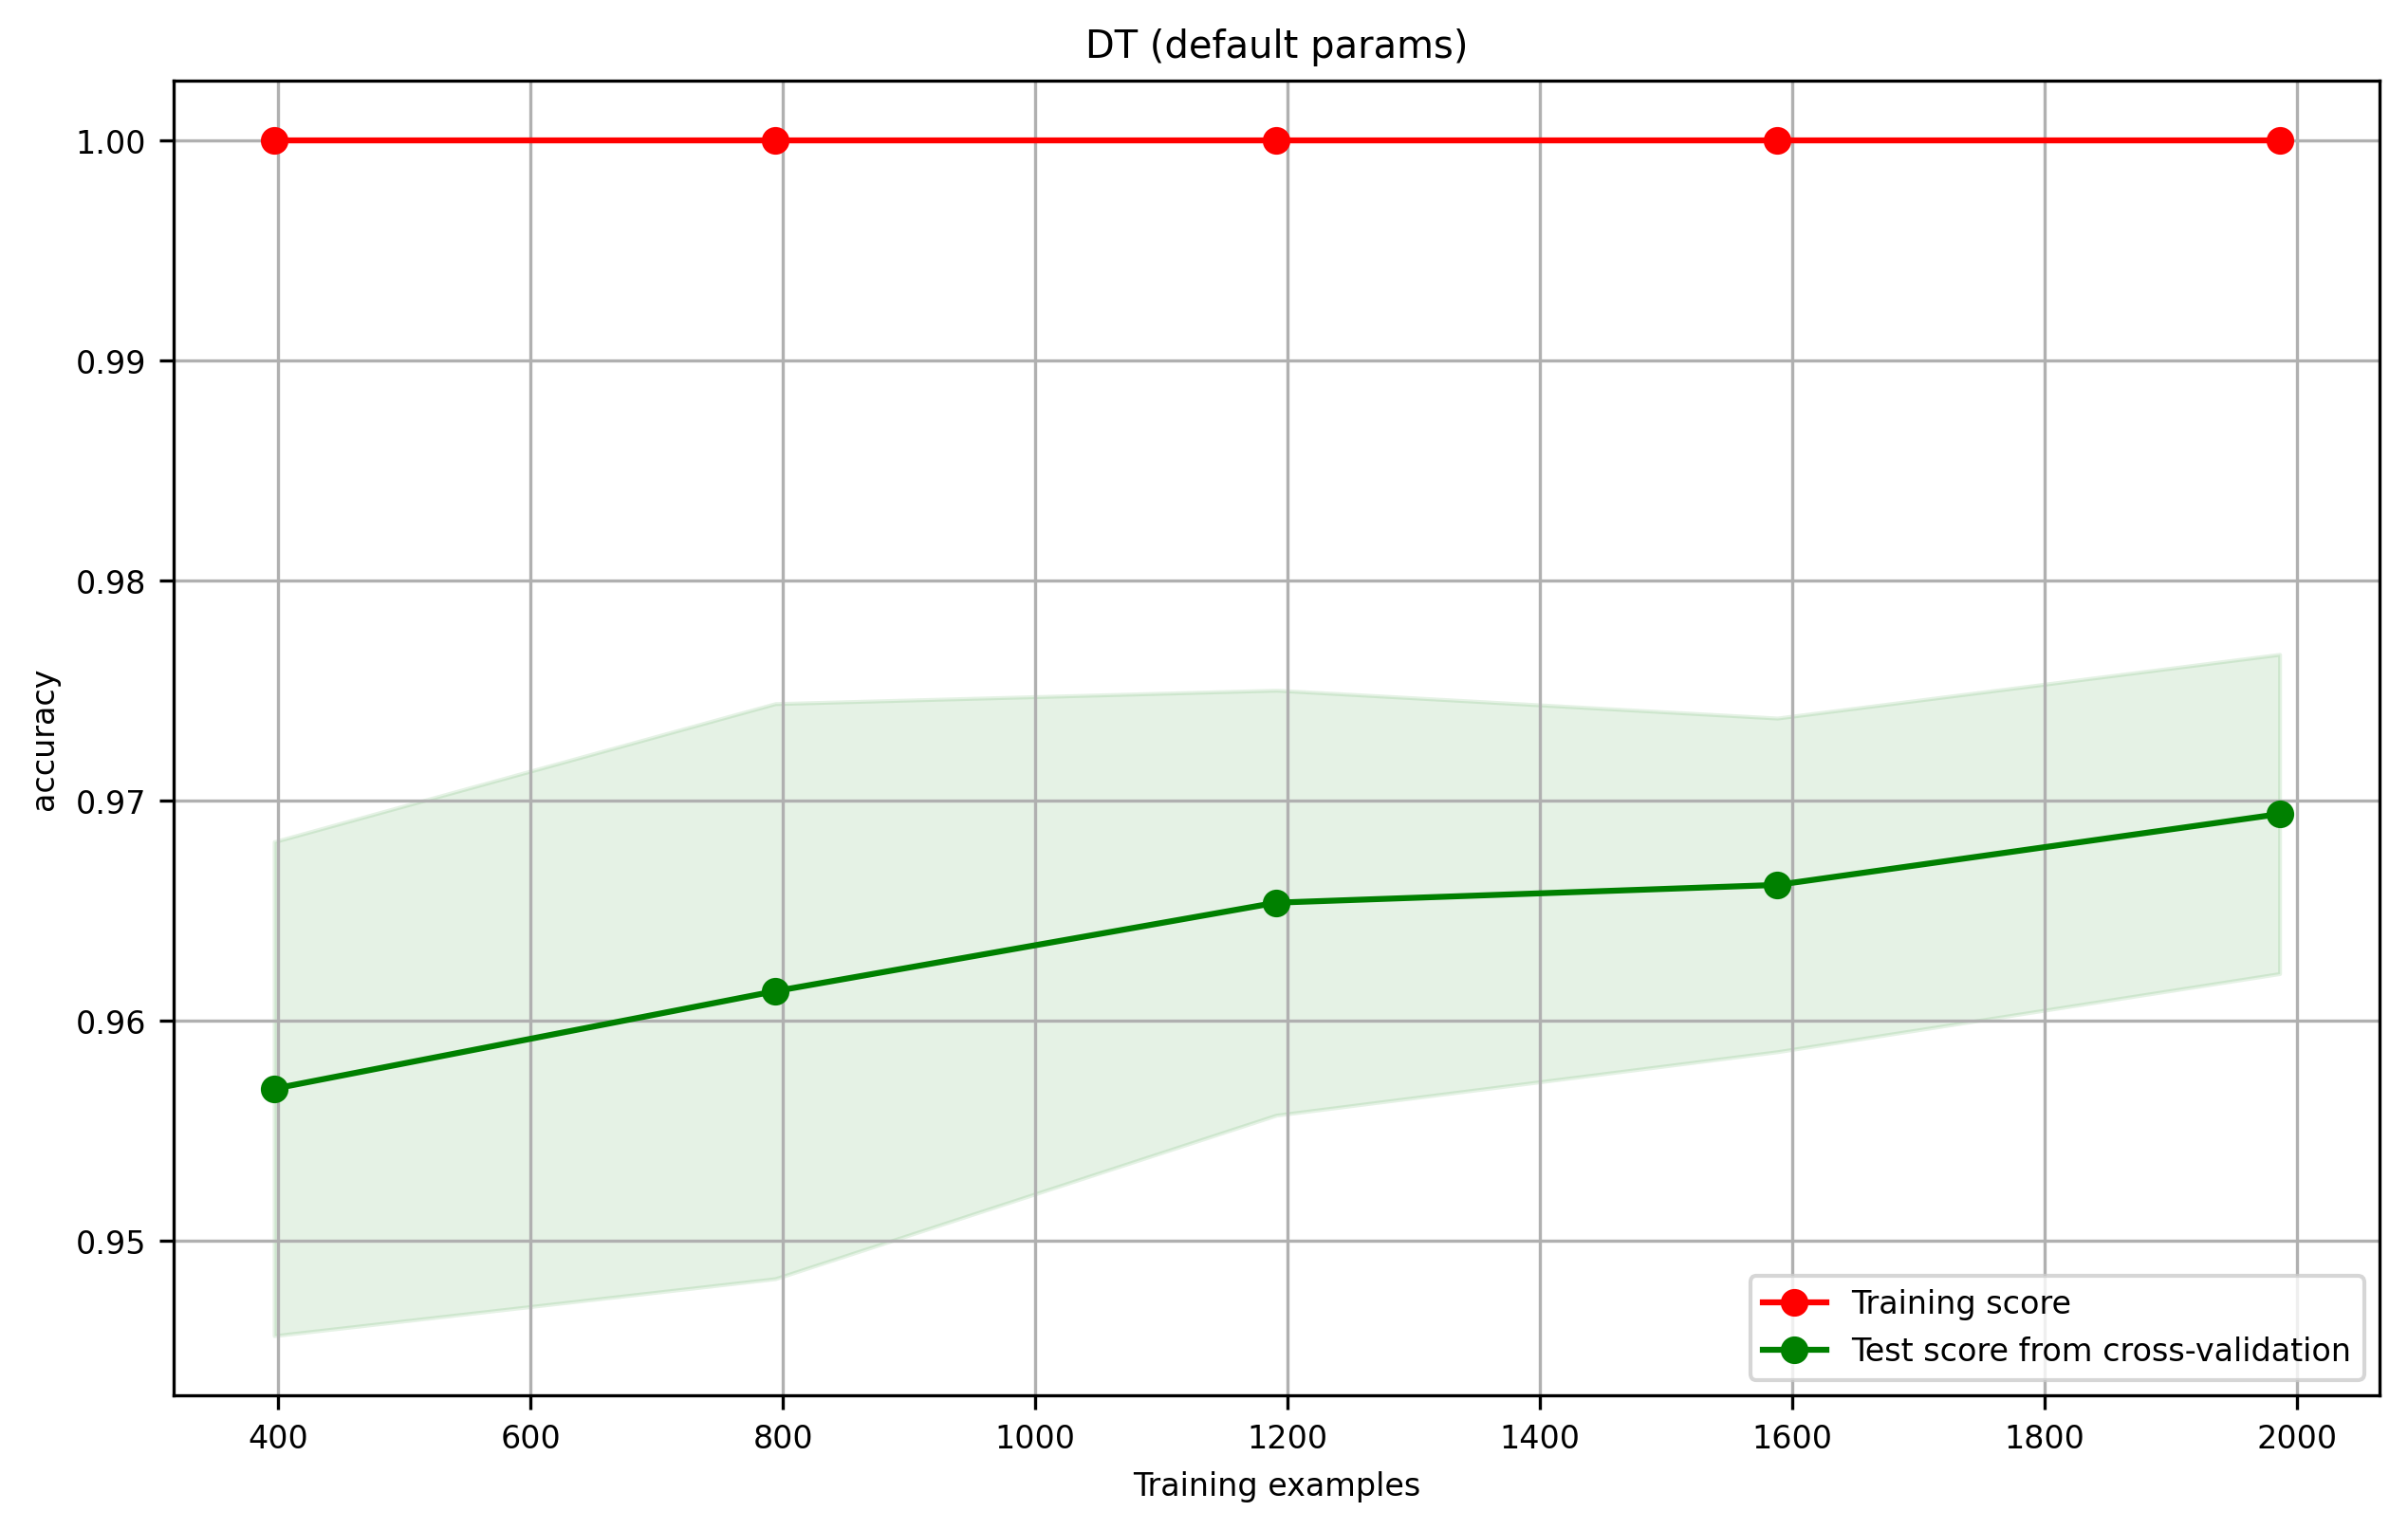

In [120]:
plot_learning_curve(model, 'DT (default params)', X, y,  cv = cv3, scoring = 'accuracy');

### **Preguntas**

Responda brevemente:

1. ¿Existe una brecha entre la curva de entrenamiento y la de validación? ¿Qué sugiere eso?

Si, existe una gran brecha entre la curva de entrenamiento y la de validación. La primera tiene un recall y un accuracy perfectos, mientras que la segunda tiene un valor de recall alrededor de 0,90 0,92 y de accuracy alrededor de 0,96 0,97.Eso sugiere que el modelo es sobre ajustado, tiene problema para tratar nuevos datos.

2. ¿El rendimiento de validación mejora al agregar más ejemplos?

Si, el rendimiento es mejor con más ejemplos. Es verdad para el recall como par el accuracy.

3. ¿Hablaría aquí de alto sesgo, alta varianza o sobreajuste moderado? Justifique.

Creo que podemos hablar aca de sobreajuste porque el modelo es perfecto para el entrenamiento y no tanto para las pruebas. Sin embargo, rendimiento superor a 0,9 no es malo y por eso podemos decir que este sobreajuste es moderado.

4. Escriba una conclusión general sobre el comportamiento del árbol base a partir de estas curvas.

 En conclusión, el árbol de decisión básico muestra signos de sobreaprendizaje. Es demasiado complejo, lo que le permite obtener una puntuación perfecta con los datos que ha visto, pero no generaliza muy bien con datos nuevos. Aunque añadir más datos ayuda un poco, el arbol es inútilmente complejo.

### Desafío: ¿un árbol más simple generaliza mejor?

Entrene ahora un segundo árbol, más restringido que el árbol base. Por ejemplo, puede probar con:

- `max_depth=3`, o
- `min_samples_leaf=10`

Luego compare su rendimiento con el árbol base usando:

- accuracy
- precision
- recall
- F1-score



In [121]:
model_tree_2 = DecisionTreeClassifier(random_state=42, max_depth=3, min_samples_leaf=10)
model_tree_2.fit(X_train, y_train)
#entrene el modelo y genere las predicciones
y_pred_2=model_tree_2.predict(X_test)

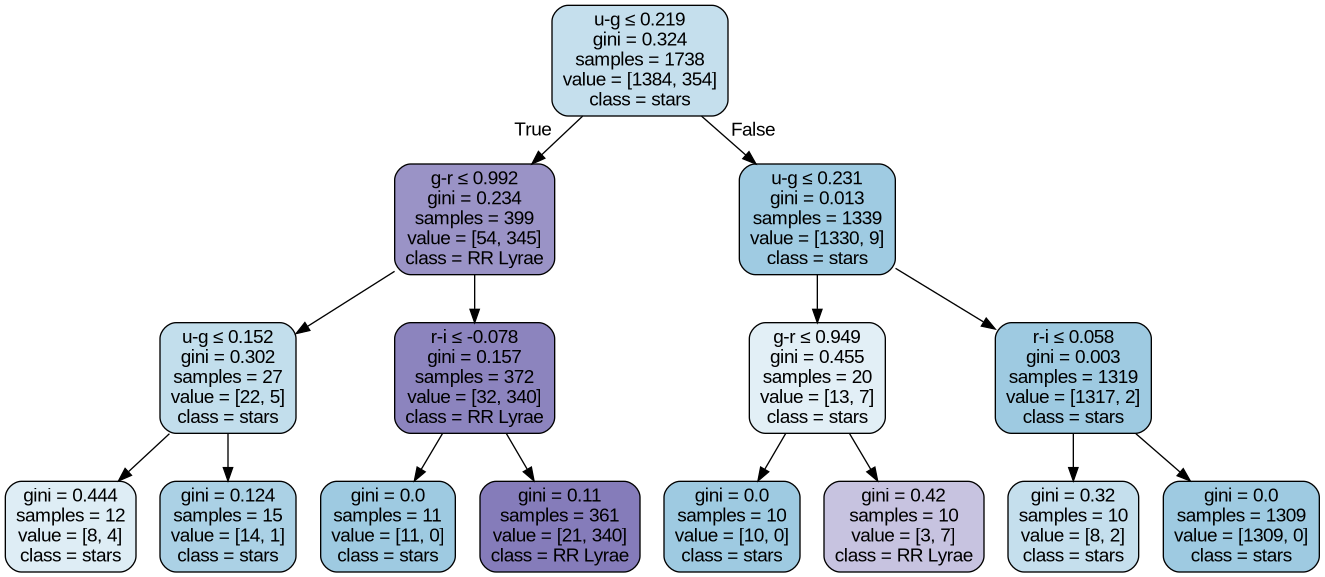

In [122]:
# Recordatorio: Las características siempre se permutan aleatoriamente en cada división.
# Por lo tanto, la mejor división encontrada puede variar, incluso con los mismos datos
# de entrenamiento y max_features=n_features, si la mejora del criterio es idéntica
# para varias divisiones enumeradas durante la búsqueda de la mejor división.
# Para obtener un comportamiento determinista durante el ajuste, random_state debe estar fijo.

dot_data = StringIO()

export_graphviz(
    model_tree_2,
    out_file=dot_data,
    feature_names=['u-g', 'g-r', 'r-i', 'i-z'],
    class_names=['stars', 'RR Lyrae'],
    filled=True,
    rounded=True,
    special_characters=True
)

graph = pydotplus.graph_from_dot_data(dot_data.getvalue().replace("\n", ""))
nodes = graph.get_node_list()

for node in nodes:
    if node.get_label() and 'value = [' in node.get_label():

        values = [float(ii) for ii in node.get_label().split('value = [')[1].split(']')[0].split(',')]
        values = [int(255 * v / sum(values)) for v in values]

        if values[0] > values[1]:
            alpha = int(values[0] - values[1])
            alpha = '{:02x}'.format(alpha)
            color = '#9ecae1' + str(alpha)   # turquesa
        else:
            alpha = int(values[1] - values[0])
            alpha = '{:02x}'.format(alpha)
            color = '#756bb1' + str(alpha)   # magenta

        node.set_fillcolor(color)

Image(graph.create_png())

In [124]:
scores_accuracy = cross_validate(model_tree, X, y, cv=cv3, scoring='accuracy')
scores_accuracy_2 = cross_validate(model_tree_2, X, y, cv=cv3, scoring='accuracy')

scores_precision = cross_validate(model_tree, X, y, cv=cv3, scoring='precision')
scores_precision_2 = cross_validate(model_tree_2, X, y, cv=cv3, scoring='precision')

scores_recall = cross_validate(model_tree, X, y, cv=cv3, scoring='recall')
scores_recall_2 = cross_validate(model_tree_2, X, y, cv=cv3, scoring='recall')

scores_f1 = cross_validate(model_tree, X, y, cv=cv3, scoring='f1')
scores_f1_2 = cross_validate(model_tree_2, X, y, cv=cv3, scoring='f1')

In [125]:
print("              Árbol base    Árbol simple")

print("Accuracy:      {:.3f}         {:.3f}".format(
    scores_accuracy['test_score'].mean(),
    scores_accuracy_2['test_score'].mean()))

print("Precision:     {:.3f}         {:.3f}".format(
    scores_precision['test_score'].mean(),
    scores_precision_2['test_score'].mean()))

print("Recall:        {:.3f}         {:.3f}".format(
    scores_recall['test_score'].mean(),
    scores_recall_2['test_score'].mean()))

print("F1-score:      {:.3f}         {:.3f}".format(
    scores_f1['test_score'].mean(),
    scores_f1_2['test_score'].mean()))

              Árbol base    Árbol simple
Accuracy:      0.971         0.973
Precision:     0.920         0.920
Recall:        0.932         0.946
F1-score:      0.926         0.933


### Preguntas

A partir de los resultados obtenidos con validación cruzada:

1. ¿Qué ocurrió con el rendimiento al restringir la complejidad del árbol?

Al restringir la complejidad del árbol, el rendimiento general mejora. El árbol simple tiene una accuracy de 0.973 frente a 0.971 para el árbol base, mientras que la precision se mantiene igual (0.920). Además, el recall aumenta de 0.932 a 0.946 y el F1-score de 0.926 a 0.933.

2. ¿El árbol más simple empeoró o mejoró la generalización?

Estos resultados sugieren que el árbol más simple generaliza ligeramente mejor que el árbol sin restricciones, especialmente porque permite detectar una mayor proporción de las estrellas RR Lyrae.

3. ¿Qué sugieren estos resultados sobre el árbol base?

El árbol base puede ser un poco más complejo de lo necesario.

4. En este problema, ¿parece conveniente usar el árbol sin restricciones?

No parece conveniente utilizarlo sin restricciones en este problema.

5. ¿Qué métrica le parece más importante para decidir entre ambos modelos?

Para comparar los dos modelos, el recall y el F1_score parecen mas importantes porque el objetivo es identificar correctamente las estrellas RR Lyrae, pero también es importante mantener una buena precision.


## Desafío: comparar con kNN

Hasta ahora trabajamos con árboles de decisión. Ahora comparemos ese enfoque con un clasificador distinto: **k-Nearest Neighbors (kNN)**.

Entrene un modelo kNN y compárelo con el árbol simple usando validación cruzada estratificada. Recuerde que kNN está basado en distancias, por lo que antes de entrenarlo debe escalar las variables.

### Instrucciones

1. Entrene un modelo kNN con `k=5`.
2. Use un `StandardScaler` antes del clasificador.
3. Evalúe el modelo con validación cruzada estratificada usando:
   - accuracy
   - precision
   - recall
   - F1-score
4. Compare sus resultados con los del árbol simple.
5. Luego explore distintos valores de `k` y vea cómo cambian las métricas.



In [126]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [127]:
knn5 = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

In [128]:
scores_accuracy_knn = cross_validate(knn5, X, y, cv=cv3, scoring='accuracy')
scores_precision_knn = cross_validate(knn5, X, y, cv=cv3, scoring='precision')
scores_recall_knn = cross_validate(knn5, X, y, cv=cv3, scoring='recall')
scores_f1_knn = cross_validate(knn5, X, y, cv=cv3, scoring='f1')

In [134]:
print("              Árbol simple    kNN (k=5)")

print("Accuracy:      {:.3f}           {:.3f}".format(
    scores_accuracy_2['test_score'].mean(),
    scores_accuracy_knn['test_score'].mean()))

print("Precision:     {:.3f}           {:.3f}".format(
    scores_precision_2['test_score'].mean(),
    scores_precision_knn['test_score'].mean()))

print("Recall:        {:.3f}           {:.3f}".format(
    scores_recall_2['test_score'].mean(),
    scores_recall_knn['test_score'].mean()))

print("F1-score:      {:.3f}           {:.3f}".format(
    scores_f1_2['test_score'].mean(),
    scores_f1_knn['test_score'].mean()))

              Árbol simple    kNN (k=5)
Accuracy:      0.973           0.978
Precision:     0.920           0.922
Recall:        0.946           0.969
F1-score:      0.933           0.945


In [135]:
k_values = [1, 3, 5, 7, 9, 11]

accuracy_knn = []
precision_knn = []
recall_knn = []
f1_knn = []

for k in k_values:
    knn = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

    accuracy_knn.append(
        cross_validate(knn, X, y, cv=cv3, scoring='accuracy')['test_score'].mean()
    )

    precision_knn.append(
        cross_validate(knn, X, y, cv=cv3, scoring='precision')['test_score'].mean()
    )

    recall_knn.append(
        cross_validate(knn, X, y, cv=cv3, scoring='recall')['test_score'].mean()
    )

    f1_knn.append(
        cross_validate(knn, X, y, cv=cv3, scoring='f1')['test_score'].mean()
    )

In [136]:
print("k    Accuracy    Precision    Recall    F1-score")

for i, k in enumerate(k_values):
    print("{:<4} {:.3f}       {:.3f}       {:.3f}     {:.3f}".format(
        k,
        accuracy_knn[i],
        precision_knn[i],
        recall_knn[i],
        f1_knn[i]
    ))

k    Accuracy    Precision    Recall    F1-score
1    0.968       0.914       0.923     0.919
3    0.977       0.923       0.961     0.941
5    0.978       0.922       0.969     0.945
7    0.978       0.918       0.975     0.946
9    0.977       0.912       0.977     0.943
11   0.977       0.907       0.981     0.943


### Preguntas

1. ¿Cómo se compara el rendimiento de kNN con el del árbol simple?

El kNN obtiene un rendimiento mejor que el árbol simple: con k=5, la accuracy es 0.978 frente a 0.973, y el recall y el F1-score también son mayores.

2. ¿Qué ocurre cuando `k` es muy pequeño?

Con es muy pequeño, los rendimientos son más bajos, el modelo es más sensible a las observaciones individuales.

3. ¿Qué ocurre cuando `k` es muy grande?

Cuando es muy grande, el recall mejora, pero la precision disminuye. El F1_score y el accuracy tambien disminuye un poco.

4. ¿Qué valor de `k` parece dar el mejor equilibrio entre precision y recall?

k=7 parece dar el mejor equilibrio.

5. ¿Qué ventaja podría tener kNN si la frontera entre clases no es rectangular?

kNN puede adaptarse mejor porque clasifica las observaciones según sus vecinos y no según reglas de separación rectangulares.

## Cierre

En esta actividad vimos que evaluar un clasificador no consiste solo en obtener un score alto, sino en interpretar qué está midiendo cada métrica y cómo se construyen los conjuntos de validación. En este problema, el uso de validación cruzada estratificada fue importante para obtener una evaluación más estable y representativa.

También observamos que un modelo más complejo no siempre generaliza mejor. Aunque el árbol base ajustaba perfectamente los datos de entrenamiento, un árbol más simple logró mejores resultados en validación cruzada, lo que sugiere que reducir la complejidad ayudó a disminuir el sobreajuste.